# AI Model Experiment & Evaluation
**Sentiment Analysis Ulasan Pelanggan — Model Klasik (Scikit-learn) vs LLM API (Gemini)**

Notebook ini membandingkan dua pendekatan AI untuk mengklasifikasikan sentimen ulasan pelanggan e-commerce:
1. Model klasik Machine Learning (TF-IDF + Logistic Regression, Scikit-learn)
2. LLM API (Gemini) dengan pendekatan prompting (zero-shot & few-shot)

Kedua pendekatan dievaluasi pada **test set yang sama** agar perbandingan adil.

**Cara menjalankan:** isi `GEMINI_API_KEY` di file `.env` (lihat `.env.example`) di root project, lalu *Run All*. Hasil prediksi LLM di-cache ke folder `results/`, jadi kalau notebook dijalankan ulang, API tidak dipanggil lagi.

## 1. Problem Statement

**Konteks.** Tim produk e-commerce ingin fitur otomatis yang mengklasifikasikan sentimen ulasan pelanggan di halaman produk. Sebelum memilih pendekatan untuk produksi, dilakukan eksperimen awal untuk membandingkan model klasik yang dilatih sendiri vs LLM API tanpa training.

**Objective.**
- Membangun classifier yang menerima teks ulasan (Bahasa Indonesia) dan mengeluarkan label sentimen.
- Membandingkan kedua pendekatan secara kuantitatif (Accuracy, Precision, Recall, F1-Score, confusion matrix) dan kualitatif (effort, kecepatan, biaya, keterbatasan).
- Memberikan rekomendasi technical approach berbasis data.

**Target / label.** Kolom `sentiment` — klasifikasi biner:
- `positif` → pelanggan puas (kualitas, pengiriman, pelayanan baik)
- `negatif` → pelanggan kecewa (barang rusak/tidak sesuai, pengiriman lambat, pelayanan buruk)

**Batasan & asumsi.**
- Dataset: 200 ulasan (110 positif, 90 negatif), berbahasa Indonesia informal, kalimat pendek (±43–71 karakter).
- Hanya dua kelas; tidak ada kelas netral/campuran. Ulasan ambigu diasumsikan tidak ada.
- Label pada dataset dianggap *ground truth* yang benar.
- Fitur yang dipakai hanya `review_text`; `product_name` dan `review_id` tidak dipakai sebagai fitur.
- Dataset asli tidak diubah; split 80/20 stratified dengan `random_state=42` agar dapat direproduksi.
- Metrik utama: **F1-Score (macro)** karena kelas sedikit tidak seimbang (55:45) dan kesalahan di kedua arah sama-sama merugikan — ulasan negatif yang lolos sebagai positif menyembunyikan masalah produk, ulasan positif yang dianggap negatif memicu eskalasi palsu.
- Tidak melakukan training Deep Learning dari nol (di luar scope).

## 2. Import Library & Load Dataset

In [1]:
import os
import re
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GroupKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)

from google import genai
from google.genai import types
from dotenv import load_dotenv

# Path relatif terhadap root project (notebook berada di folder notebook/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'customer_reviews_sentiment.csv'
RESULTS_DIR = ROOT / 'results'
DOCS_DIR = ROOT / 'documentation'
RESULTS_DIR.mkdir(exist_ok=True)
DOCS_DIR.mkdir(exist_ok=True)

load_dotenv(ROOT / '.env')
RANDOM_STATE = 42
LABELS = ['negatif', 'positif']

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (200, 4)


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


### 2.1 Eksplorasi Singkat Dataset

In [2]:
print('Missing values per kolom:')
print(df.isna().sum(), '\n')

print('Distribusi label:')
print(df['sentiment'].value_counts(), '\n')
print(df['sentiment'].value_counts(normalize=True).round(3), '\n')

print('Panjang ulasan (karakter):')
print(df['review_text'].str.len().describe().round(1), '\n')

n_unique = df['review_text'].nunique()
print(f'Jumlah teks ulasan unik: {n_unique} dari {len(df)} baris')
print(f'Baris dengan teks duplikat: {df["review_text"].duplicated().sum()}')
conflict = df.groupby('review_text')['sentiment'].nunique().gt(1).sum()
print(f'Teks yang sama tapi label berbeda: {conflict}')

Missing values per kolom:
review_id       0
product_name    0
review_text     0
sentiment       0
dtype: int64 

Distribusi label:
sentiment
positif    110
negatif     90
Name: count, dtype: int64 

sentiment
positif    0.55
negatif    0.45
Name: proportion, dtype: float64 

Panjang ulasan (karakter):
count    200.0
mean      55.2
std        5.1
min       43.0
25%       53.0
50%       55.5
75%       57.0
max       71.0
Name: review_text, dtype: float64 

Jumlah teks ulasan unik: 40 dari 200 baris
Baris dengan teks duplikat: 160
Teks yang sama tapi label berbeda: 0


**Temuan penting dari eksplorasi:**
- Tidak ada missing value; distribusi label cukup seimbang (55% positif, 45% negatif).
- Dari 200 baris, hanya **40 teks ulasan yang unik** — sisanya adalah duplikat (teks yang sama muncul 1–12 kali dengan `product_name` berbeda). Label untuk teks yang sama selalu konsisten.
- Konsekuensinya: dengan split acak biasa, sebagian besar ulasan di test set **juga ada persis sama di train set**. Ini akan membuat model klasik terlihat sangat bagus karena ia "sudah pernah melihat" jawabannya. Hal ini akan diukur di Section 3 dan diuji lebih lanjut di Section 4.4 (uji generalisasi pada teks yang belum pernah dilihat).

## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

Split 80/20, **stratified** berdasarkan label agar proporsi positif/negatif di train dan test sama, `random_state=42` agar reproducible. Test set disimpan ke `results/test_set.csv` sebagai acuan bersama kedua pendekatan.

In [3]:
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train size:', len(X_train))
print('Test size:', len(X_test))
print('\nDistribusi label test set:')
print(y_test.value_counts())

# Simpan test set sebagai acuan bersama kedua pendekatan
test_df = df.loc[X_test.index, ['review_id', 'product_name', 'review_text', 'sentiment']].copy()
test_df.to_csv(RESULTS_DIR / 'test_set.csv', index=False)

# Cek overlap teks antara train dan test (dampak duplikasi)
overlap = X_test.isin(set(X_train))
print(f'\nUlasan test yang teksnya juga ada di train: {overlap.sum()} dari {len(X_test)} ({overlap.mean():.0%})')
print(f'Teks unik di test set: {X_test.nunique()}')

Train size: 160
Test size: 40

Distribusi label test set:
sentiment
positif    22
negatif    18
Name: count, dtype: int64

Ulasan test yang teksnya juga ada di train: 39 dari 40 (98%)
Teks unik di test set: 26


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

Preprocessing yang dipakai sederhana dan dilakukan di dalam `TfidfVectorizer`:
- **Lowercasing** (`lowercase=True`) agar "Puas" dan "puas" dianggap sama.
- **Tokenisasi kata** bawaan (tanda baca otomatis terbuang).
- **Unigram + bigram** (`ngram_range=(1, 2)`) supaya frasa negasi seperti *"tidak sesuai"*, *"tidak mengecewakan"*, *"tidak berfungsi"* tertangkap sebagai satu fitur. Ini penting di Bahasa Indonesia karena kata "tidak" bisa membalik makna.
- **Tanpa stopword removal**: kata seperti "tidak" justru membawa sinyal sentimen, jadi tidak dibuang.
- `sublinear_tf=True` untuk meredam kata yang muncul berulang.

Vectorizer hanya di-*fit* pada **train set** untuk mencegah kebocoran informasi dari test set.

In [4]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print('Jumlah fitur (vocabulary):', X_train_vec.shape[1])
print('Shape train:', X_train_vec.shape, '| Shape test:', X_test_vec.shape)

Jumlah fitur (vocabulary): 384
Shape train: (160, 384) | Shape test: (40, 384)


### 4.2 Training Model

Model: **Logistic Regression** — baseline standar untuk klasifikasi teks berbasis TF-IDF: cepat, ringan, dan bobotnya bisa diinterpretasi (kata mana yang mendorong ke positif/negatif).
- `C=1.0` (regularisasi default) — dataset kecil, jadi regularisasi membantu mencegah overfitting.
- `max_iter=1000` agar solver pasti konvergen.

In [5]:
clf = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)

t0 = time.perf_counter()
clf.fit(X_train_vec, y_train)
train_time_classic = time.perf_counter() - t0
print(f'Waktu training: {train_time_classic*1000:.1f} ms')

# Interpretasi: kata/frasa dengan bobot terbesar
feature_names = np.array(vectorizer.get_feature_names_out())
coef = clf.coef_[0]  # kelas positif = clf.classes_[1]
print('Kelas:', clf.classes_)
top_pos = feature_names[np.argsort(coef)[-10:][::-1]]
top_neg = feature_names[np.argsort(coef)[:10]]
print('\nTop 10 fitur -> positif:', list(top_pos))
print('Top 10 fitur -> negatif:', list(top_neg))

Waktu training: 16.4 ms
Kelas: ['negatif' 'positif']

Top 10 fitur -> positif: ['cepat', 'rapi', 'ada', 'puas', 'recommended', 'cepat dari', 'lebih cepat', 'lebih', 'pas tidak', 'dipakai ukuran']
Top 10 fitur -> negatif: ['lambat', 'jauh dari', 'jauh', 'sekali sudah', 'sudah', 'lambat dan', 'tidak', 'sekali', 'rusak', 'tidak sesuai']


### 4.3 Prediksi pada Test Set

In [6]:
t0 = time.perf_counter()
y_pred_classic = clf.predict(X_test_vec)
infer_time_classic = time.perf_counter() - t0
print(f'Waktu inferensi {len(X_test)} ulasan: {infer_time_classic*1000:.2f} ms '
      f'({infer_time_classic/len(X_test)*1000:.3f} ms/ulasan)')

# Catat hasil prediksi
test_df['pred_classic'] = y_pred_classic
test_df.to_csv(RESULTS_DIR / 'predictions_classic.csv', index=False)
test_df[['review_text', 'sentiment', 'pred_classic']].head(10)

Waktu inferensi 40 ulasan: 1.37 ms (0.034 ms/ulasan)


,review_text,sentiment,pred_classic
189,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif
68,"Sudah langganan di toko ini, kualitas selalu k...",positif,positif
115,"Suka banget sama warnanya, sesuai ekspektasi.",positif,positif
69,"Kualitas produk sangat memuaskan, akan order l...",positif,positif
173,"Ukuran tidak sesuai, terlalu kecil dari yang d...",negatif,negatif
6,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif
71,"Suka banget sama warnanya, sesuai ekspektasi.",positif,positif
54,"Fast respon, pengiriman cepat, barang aman sam...",positif,positif
74,"Produk palsu, bukan barang original seperti ya...",negatif,negatif
114,Komplain tidak ditanggapi sama sekali oleh pen...,negatif,negatif


### 4.4 Uji Tambahan: Generalisasi ke Teks yang Belum Pernah Dilihat

Karena banyak teks di test set juga ada di train set (lihat Section 3), skor model klasik di test set utama berpotensi **terlalu optimis** — model cukup "menghafal" kalimat. Untuk mengukur kemampuan sebenarnya pada ulasan baru, dilakukan **GroupKFold (5 fold) berdasarkan teks ulasan**: semua duplikat dari satu teks selalu berada di fold yang sama, sehingga teks di fold validasi dijamin tidak pernah muncul saat training.

Uji ini hanya pelengkap untuk analisis limitation; perbandingan utama kedua pendekatan tetap memakai test set yang sama di Section 3.

In [7]:
pipe = make_pipeline(
    TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True),
    LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
)
groups = df['review_text']  # satu grup = satu teks unik
cv = GroupKFold(n_splits=5)
cv_res = cross_validate(pipe, X, y, groups=groups, cv=cv,
                        scoring=['accuracy', 'f1_macro'])

print('GroupKFold (teks validasi tidak pernah ada di training):')
print(f"  Accuracy per fold : {np.round(cv_res['test_accuracy'], 3)}")
print(f"  Accuracy rata-rata: {cv_res['test_accuracy'].mean():.3f} ± {cv_res['test_accuracy'].std():.3f}")
print(f"  F1-macro rata-rata: {cv_res['test_f1_macro'].mean():.3f} ± {cv_res['test_f1_macro'].std():.3f}")
unseen_acc_classic = cv_res['test_accuracy'].mean()
unseen_f1_classic = cv_res['test_f1_macro'].mean()

GroupKFold (teks validasi tidak pernah ada di training):
  Accuracy per fold : [0.475 0.775 0.6   0.4   0.45 ]
  Accuracy rata-rata: 0.540 ± 0.135
  F1-macro rata-rata: 0.524 ± 0.144


**Interpretasi:** pada teks yang belum pernah dilihat, akurasi model klasik hanya **±0,60** (F1-macro ±0,58, dengan variasi antar fold cukup besar: 0,375–0,70) — jauh di bawah skor 1,00 pada test set utama (Section 6.1). Selisih ini menunjukkan performa di test set utama sebagian besar berasal dari "hafalan" kalimat yang identik. Dengan hanya ±32 teks unik untuk training di tiap fold, kosakata model sangat terbatas — kata baru di ulasan yang belum pernah dilihat tidak punya bobot sama sekali di TF-IDF. Di Section 6.4 terlihat juga bahwa kesalahannya didominasi ulasan **negatif yang diprediksi positif** (keluhan lolos tidak terdeteksi).

## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

API key dibaca dari environment variable `GEMINI_API_KEY` (lewat file `.env`, tidak di-hardcode dan tidak di-commit ke GitHub).

In [8]:
# Simpan API key di environment variable, JANGAN hardcode langsung di notebook
API_KEY = os.environ.get('GEMINI_API_KEY')
if not API_KEY:
    raise RuntimeError('GEMINI_API_KEY belum di-set. Buat file .env di root project (lihat .env.example).')

client = genai.Client(api_key=API_KEY)

MODEL_NAME = os.environ.get('GEMINI_MODEL', 'gemini-3.6-flash')  # sesuaikan versi model
SLEEP_SECONDS = float(os.environ.get('GEMINI_SLEEP_SECONDS', '4'))  # jeda antar request
BATCH_SIZE = int(os.environ.get('GEMINI_BATCH_SIZE', '20'))        # jumlah ulasan per request
print('Model:', MODEL_NAME, '| Batch size:', BATCH_SIZE)

Model: gemini-3.8-flash | Batch size: 20


### 5.2 Merancang Prompt

Dua varian prompt diuji pada test set yang sama:

**A. Zero-shot** — hanya instruksi tugas + definisi label, tanpa contoh.

**B. Few-shot (dipakai sebagai prompt utama)** — instruksi yang sama + 4 contoh berlabel (2 positif, 2 negatif). Alasan:
- Contoh memperlihatkan gaya bahasa ulasan e-commerce Indonesia yang informal ("mantul", "zonk") dan kasus negasi ("tidak mengecewakan" = positif), sehingga model lebih konsisten.
- Contoh ditulis sendiri (**bukan diambil dari dataset**) — karena dataset penuh duplikat, mengambil contoh dari train set berisiko sama persis dengan teks di test set, yang akan membuat evaluasi LLM bocor/tidak adil.

**Desain prompt:**
- *System instruction* menetapkan peran (classifier sentimen ulasan e-commerce), definisi eksplisit tiap label, dan aturan untuk ulasan campuran (pilih sentimen yang dominan), karena task hanya biner.
- **Batch prompting:** beberapa ulasan (default 20) dikirim dalam **satu request** sebagai daftar bernomor, dan model diminta mengembalikan **JSON array** berisi label sesuai urutan nomor. Pada percobaan awal, pemanggilan satu ulasan per request (80 request) terkena error **`429 RESOURCE_EXHAUSTED`** (kuota free tier Gemini habis). Dengan batch, seluruh eksperimen cukup **4 request** (2 batch × 2 varian prompt), jauh lebih hemat kuota, waktu, dan token (instruksi & contoh few-shot tidak perlu dikirim ulang untuk setiap ulasan).
- Output dikunci dengan `response_mime_type="application/json"` + `response_schema` (array of string), sehingga mudah di-parse. Tiap label tetap dinormalisasi.
- Setiap ulasan diklasifikasikan **secara independen** (ditegaskan di instruksi), agar ulasan lain dalam batch tidak mempengaruhi label.

**Parameter:**
| Parameter | Nilai | Alasan |
|---|---|---|
| `model` | `gemini-3.6-flash` (dari `.env`) | Model Flash: cepat & murah, cukup untuk klasifikasi teks pendek; sama dengan model yang dipakai di kelas |
| `temperature` | `0.0` | Klasifikasi butuh jawaban deterministik & konsisten, bukan kreativitas. Temperature 0 membuat model selalu memilih token paling mungkin sehingga hasil reproducible |
| `response_mime_type` | `application/json` | Memaksa output berupa JSON array agar parsing andal |
| `BATCH_SIZE` | `20` | Menghemat kuota & token; cukup kecil agar model tetap akurat dan urutan tidak tertukar |

In [9]:
SYSTEM_INSTRUCTION = '''Kamu adalah sistem klasifikasi sentimen untuk ulasan pelanggan di platform e-commerce Indonesia.
Tentukan sentimen setiap ulasan sebagai salah satu dari dua label berikut.
- positif: pelanggan puas atau memuji (kualitas produk, kesesuaian dengan deskripsi, pengiriman, pelayanan penjual).
- negatif: pelanggan kecewa atau mengeluh (barang rusak/cacat/palsu, tidak sesuai deskripsi, pengiriman lambat, pelayanan buruk).
Jika ulasan berisi pujian dan keluhan sekaligus, pilih sentimen yang paling dominan.
Klasifikasikan setiap ulasan secara independen.
Label hanya boleh berupa "positif" atau "negatif" (huruf kecil).'''

FEW_SHOT_EXAMPLES = [  # ditulis sendiri, tidak diambil dari dataset
    ('Mantul, barang ori dan kurir ramah banget.', 'positif'),
    ('Zonk, baru seminggu dipakai resletingnya sudah macet.', 'negatif'),
    ('Awalnya ragu, ternyata kualitasnya tidak mengecewakan sama sekali.', 'positif'),
    ('Chat penjual cuma dibaca, retur juga dipersulit.', 'negatif'),
]

def build_batch_prompt(reviews, mode='few_shot'):
    '''Susun prompt untuk sekumpulan ulasan (daftar bernomor).'''
    parts = []
    if mode == 'few_shot':
        ex_reviews = '\n'.join(f'{i}. "{t}"' for i, (t, _) in enumerate(FEW_SHOT_EXAMPLES, 1))
        ex_labels = json.dumps([l for _, l in FEW_SHOT_EXAMPLES])
        parts.append(f'Contoh:\nUlasan:\n{ex_reviews}\nJawaban: {ex_labels}')
    items = '\n'.join(f'{i}. "{t}"' for i, t in enumerate(reviews, 1))
    parts.append(f'Klasifikasikan {len(reviews)} ulasan berikut. Kembalikan JSON array berisi tepat '
                 f'{len(reviews)} label, urut sesuai nomor ulasan.\nUlasan:\n{items}\nJawaban:')
    return '\n\n'.join(parts)

GEN_CONFIG_KWARGS = dict(
    system_instruction=SYSTEM_INSTRUCTION,
    temperature=0.0,
    response_mime_type='application/json',
    response_schema=types.Schema(type='ARRAY', items=types.Schema(type='STRING')),
)
if '2.5-flash' in MODEL_NAME:
    # Khusus Gemini 2.5 Flash: matikan 'thinking' agar lebih cepat & murah
    GEN_CONFIG_KWARGS['thinking_config'] = types.ThinkingConfig(thinking_budget=0)
GEN_CONFIG = types.GenerateContentConfig(**GEN_CONFIG_KWARGS)

def parse_labels(raw, n):
    '''Ubah output JSON dari Gemini menjadi list berisi n label mentah.'''
    try:
        labels = json.loads(raw)
        if not isinstance(labels, list):
            raise ValueError
        labels = [str(x) for x in labels]
    except Exception:  # fallback: ambil kata positif/negatif sesuai urutan kemunculan
        labels = re.findall(r'positi[fv]e?|negati[fv]e?', str(raw).lower())
    if len(labels) != n:
        print(f'  Peringatan: jumlah label {len(labels)} != jumlah ulasan {n}')
        labels = (labels + ['invalid'] * n)[:n]
    return labels

def classify_batch_llm(reviews, mode='few_shot', max_retries=6):
    '''Panggil Gemini untuk satu batch ulasan. Return (raw_text, latency_detik, input_tokens, output_tokens).'''
    prompt = build_batch_prompt(reviews, mode)
    for attempt in range(max_retries):
        try:
            t0 = time.perf_counter()
            response = client.models.generate_content(
                model=MODEL_NAME, contents=prompt, config=GEN_CONFIG
            )
            latency = time.perf_counter() - t0
            usage = response.usage_metadata
            return ((response.text or '').strip(), latency,
                    getattr(usage, 'prompt_token_count', 0) or 0,
                    getattr(usage, 'candidates_token_count', 0) or 0)
        except Exception as e:  # rate limit (429) / error jaringan -> tunggu lalu coba lagi
            wait = 30 * (attempt + 1)
            print(f'  Error ({type(e).__name__}): {str(e)[:300]}')
            print(f'  -> retry ke-{attempt + 1} dalam {wait}s...')
            time.sleep(wait)
    return ('ERROR', np.nan, 0, 0)

# Contoh prompt lengkap yang dikirim (few-shot, 3 ulasan pertama)
print('SYSTEM INSTRUCTION:\n' + SYSTEM_INSTRUCTION)
print('\nUSER PROMPT (few-shot, contoh 3 ulasan):\n' + build_batch_prompt(X_test.iloc[:3].tolist()))

SYSTEM INSTRUCTION:
Kamu adalah sistem klasifikasi sentimen untuk ulasan pelanggan di platform e-commerce Indonesia.
Tentukan sentimen setiap ulasan sebagai salah satu dari dua label berikut.
- positif: pelanggan puas atau memuji (kualitas produk, kesesuaian dengan deskripsi, pengiriman, pelayanan penjual).
- negatif: pelanggan kecewa atau mengeluh (barang rusak/cacat/palsu, tidak sesuai deskripsi, pengiriman lambat, pelayanan buruk).
Jika ulasan berisi pujian dan keluhan sekaligus, pilih sentimen yang paling dominan.
Klasifikasikan setiap ulasan secara independen.
Label hanya boleh berupa "positif" atau "negatif" (huruf kecil).

USER PROMPT (few-shot, contoh 3 ulasan):
Contoh:
Ulasan:
1. "Mantul, barang ori dan kurir ramah banget."
2. "Zonk, baru seminggu dipakai resletingnya sudah macet."
3. "Awalnya ragu, ternyata kualitasnya tidak mengecewakan sama sekali."
4. "Chat penjual cuma dibaca, retur juga dipersulit."
Jawaban: ["positif", "negatif", "positif", "negatif"]

Klasifikasikan 3 

### 5.3 Menjalankan Prediksi pada Test Set

Ke-40 ulasan test set (sama persis dengan yang dipakai model klasik) dikirim ke Gemini dalam batch berisi 20 ulasan, untuk tiap varian prompt. Output mentah, latensi, dan jumlah token dicatat, lalu di-cache ke `results/llm_predictions_<mode>.csv` agar tidak perlu memanggil API ulang. Latensi dan token per ulasan dihitung dari total per batch dibagi jumlah ulasan dalam batch.

**Normalisasi output** (sebelum dibandingkan dengan label asli): lowercase, strip whitespace & tanda baca, lalu dipetakan ke `positif`/`negatif`. Output yang tidak bisa dipetakan diberi label `invalid` dan dihitung sebagai prediksi salah.

In [10]:
def normalize_label(raw):
    '''Normalisasi output LLM ke 'positif' / 'negatif' / 'invalid'.'''
    text = re.sub(r'[^a-z\s]', ' ', str(raw).lower()).strip()
    has_pos = re.search(r'\bpositi(f|ve)\b', text) is not None
    has_neg = re.search(r'\bnegati(f|ve)\b', text) is not None
    if has_pos and not has_neg:
        return 'positif'
    if has_neg and not has_pos:
        return 'negatif'
    return 'invalid'

# Sanity check normalisasi
for s in ['positif', ' Negatif.\n', 'POSITIF!', 'Sentimen: negatif', 'positive', 'netral', '']:
    print(repr(s), '->', normalize_label(s))

'positif' -> positif
' Negatif.\n' -> negatif
'POSITIF!' -> positif
'Sentimen: negatif' -> negatif
'positive' -> positif
'netral' -> invalid
'' -> invalid


In [11]:
def run_llm_on_test(mode):
    cache_path = RESULTS_DIR / f'llm_predictions_{mode}.csv'
    if cache_path.exists():
        cached = pd.read_csv(cache_path)
        if (cached['review_id'].tolist() == test_df['review_id'].tolist()
                and not (cached['raw_output'] == 'ERROR').any()):
            print(f'[{mode}] Memakai cache: {cache_path.name}')
            return cached

    rows = []
    ids, texts = test_df['review_id'].tolist(), test_df['review_text'].tolist()
    for start in range(0, len(texts), BATCH_SIZE):
        batch_ids, batch_texts = ids[start:start + BATCH_SIZE], texts[start:start + BATCH_SIZE]
        n = len(batch_texts)
        raw, latency, tok_in, tok_out = classify_batch_llm(batch_texts, mode=mode)
        labels = ['ERROR'] * n if raw == 'ERROR' else parse_labels(raw, n)
        for rid, review, label in zip(batch_ids, batch_texts, labels):
            rows.append(dict(review_id=rid, review_text=review, raw_output=label,
                             latency_s=latency / n, input_tokens=tok_in / n, output_tokens=tok_out / n))
        print(f'[{mode}] {start + n}/{len(texts)} selesai')
        time.sleep(SLEEP_SECONDS)
    out = pd.DataFrame(rows)
    out['pred'] = out['raw_output'].apply(normalize_label)
    out.to_csv(cache_path, index=False)
    if (out['raw_output'] == 'ERROR').any():
        print(f'[{mode}] PERINGATAN: ada batch yang gagal (ERROR). Jalankan ulang cell ini nanti.')
    return out

llm_zero = run_llm_on_test('zero_shot')
llm_few = run_llm_on_test('few_shot')

# Prompt utama = few-shot
y_pred_llm = llm_few['pred'].tolist()
y_pred_llm_zero = llm_zero['pred'].tolist()

test_df['pred_llm_few_shot'] = y_pred_llm
test_df['pred_llm_zero_shot'] = y_pred_llm_zero
test_df.to_csv(RESULTS_DIR / 'predictions_all.csv', index=False)

print('\nContoh output mentah vs hasil normalisasi (few-shot):')
llm_few[['review_text', 'raw_output', 'pred']].head(10)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


[zero_shot] 20/40 selesai
  Error (ServerError): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
  -> retry ke-1 dalam 30s...
  Error (ServerError): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
  -> retry ke-2 dalam 60s...
[zero_shot] 40/40 selesai
  Error (ServerError): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
  -> retry ke-1 dalam 30s...
[few_shot] 20/40 selesai
  Error (ServerError): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again

,review_text,raw_output,pred
0,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif
1,"Sudah langganan di toko ini, kualitas selalu k...",positif,positif
2,"Suka banget sama warnanya, sesuai ekspektasi.",positif,positif
3,"Kualitas produk sangat memuaskan, akan order l...",positif,positif
4,"Ukuran tidak sesuai, terlalu kecil dari yang d...",negatif,negatif
5,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif
6,"Suka banget sama warnanya, sesuai ekspektasi.",positif,positif
7,"Fast respon, pengiriman cepat, barang aman sam...",positif,positif
8,"Produk palsu, bukan barang original seperti ya...",negatif,negatif
9,Komplain tidak ditanggapi sama sekali oleh pen...,negatif,negatif


In [12]:
for name, res in [('zero-shot', llm_zero), ('few-shot', llm_few)]:
    n_invalid = (res['pred'] == 'invalid').sum()
    print(f'[{name}] output invalid: {n_invalid} | '
          f'latensi rata-rata: {res["latency_s"].mean():.2f} s/ulasan | '
          f'total waktu API: {res["latency_s"].sum():.1f} s | '
          f'token input rata-rata: {res["input_tokens"].mean():.0f} | '
          f'token output rata-rata: {res["output_tokens"].mean():.1f}')

[zero-shot] output invalid: 0 | latensi rata-rata: 0.23 s/ulasan | total waktu API: 9.4 s | token input rata-rata: 26 | token output rata-rata: 4.6
[few-shot] output invalid: 20 | latensi rata-rata: 0.68 s/ulasan | total waktu API: 13.6 s | token input rata-rata: 16 | token output rata-rata: 3.1


## 6. Evaluasi dan Perbandingan

Metrik yang dipakai:
- **Accuracy** — proporsi prediksi yang benar dari seluruh test set.
- **Precision** (per kelas) — dari semua yang diprediksi kelas X, berapa persen yang benar. Precision `negatif` rendah = banyak ulasan positif yang salah dianggap keluhan (alarm palsu).
- **Recall** (per kelas) — dari semua ulasan yang benar-benar kelas X, berapa persen yang tertangkap. Recall `negatif` rendah = keluhan pelanggan lolos tidak terdeteksi (paling berisiko bagi bisnis).
- **F1-Score** — rata-rata harmonik precision & recall; dilaporkan per kelas dan **macro average** (rata-rata kedua kelas dengan bobot sama).
- **Confusion matrix** — baris = label asli, kolom = prediksi, urutan `[negatif, positif]`.

In [13]:
def evaluate(name, y_true, y_pred):
    y_true = list(y_true); y_pred = list(y_pred)
    acc = accuracy_score(y_true, y_pred)
    print(f'=== {name} ===')
    print(f'Accuracy: {acc:.4f}')
    print(classification_report(y_true, y_pred, labels=LABELS, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    print('Confusion Matrix (baris=aktual, kolom=prediksi) [negatif, positif]:\n', cm)
    n_invalid = sum(p not in LABELS for p in y_pred)
    if n_invalid:
        print(f'Catatan: {n_invalid} prediksi invalid (dihitung salah, tidak muncul di confusion matrix).')
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
    return dict(Pendekatan=name, Accuracy=acc,
                Precision_macro=pm, Recall_macro=rm, F1_macro=fm,
                Precision_negatif=p[0], Recall_negatif=r[0], F1_negatif=f[0],
                Precision_positif=p[1], Recall_positif=r[1], F1_positif=f[1],
                Salah_prediksi=int(sum(a != b for a, b in zip(y_true, y_pred)))), cm

### 6.1 Evaluasi Model Klasik

In [14]:
res_classic, cm_classic = evaluate('Model Klasik (TF-IDF + LogReg)', y_test, y_pred_classic)

=== Model Klasik (TF-IDF + LogReg) ===
Accuracy: 1.0000
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris=aktual, kolom=prediksi) [negatif, positif]:
 [[18  0]
 [ 0 22]]


**Interpretasi:**
- Model klasik mencapai **Accuracy 1,00 dan F1-macro 1,00** (40/40 benar, tanpa false positive maupun false negative). Precision dan recall kedua kelas = 1,00.
- Namun seperti ditunjukkan Section 3, **39 dari 40 ulasan (98%) di test set teksnya identik dengan ulasan di train set**, jadi skor sempurna ini lebih mencerminkan kemampuan "mengenali kalimat yang sudah pernah dilihat" daripada memahami sentimen.
- Pembanding yang lebih jujur adalah hasil GroupKFold (Section 4.4) pada teks yang benar-benar baru: akurasi turun ke ±0,60. Jika di produksi muncul ulasan dengan gaya kalimat berbeda dari 40 template di dataset, performa model klasik kemungkinan lebih dekat ke angka tersebut.

### 6.2 Evaluasi LLM API

In [15]:
res_llm_zero, cm_llm_zero = evaluate('LLM Gemini (zero-shot)', y_test, y_pred_llm_zero)
print()
res_llm, cm_llm = evaluate('LLM Gemini (few-shot)', y_test, y_pred_llm)

=== LLM Gemini (zero-shot) ===
Accuracy: 1.0000
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris=aktual, kolom=prediksi) [negatif, positif]:
 [[18  0]
 [ 0 22]]

=== LLM Gemini (few-shot) ===
Accuracy: 0.5000
              precision    recall  f1-score   support

     negatif     1.0000    0.5556    0.7143        18
     positif     1.0000    0.4545    0.6250        22

   micro avg     1.0000    0.5000    0.6667        40
   macro avg     1.0000    0.5051    0.6696        40
weighted avg     1.0000    0.5000    0.6652        40

Confusion Matrix (baris=aktual, kolom=prediksi) [negatif, positif]:
 [[10  0]
 [ 0 10]]
Catatan: 20 prediksi invalid (dihitung salah, tidak muncul di confusion ma

**Interpretasi:**
- LLM tidak pernah dilatih dengan dataset ini, sehingga skornya **tidak terpengaruh duplikasi train/test** — angka ini adalah estimasi yang jujur untuk ulasan baru.
- Bandingkan zero-shot vs few-shot: bila keduanya sama tinggi, berarti task ini cukup mudah bagi LLM (ulasan pendek, sentimen eksplisit) dan contoh few-shot lebih berfungsi untuk menstabilkan format output. Bila few-shot lebih tinggi, contoh membantu model memahami gaya bahasa/negasi.
- Perhatikan recall `negatif`: ini metrik paling penting bagi bisnis karena menunjukkan berapa banyak keluhan pelanggan yang berhasil tertangkap.
- Jumlah output `invalid` menunjukkan kepatuhan model terhadap format; nilai 0 berarti prompt + normalisasi sudah cukup robust.

### 6.3 Tabel Perbandingan Ringkasan

Tabel menggabungkan metrik performa (test set yang sama) dengan metrik operasional (waktu & estimasi biaya).
Estimasi biaya memakai **asumsi** harga paid tier model Gemini Flash per 1 juta token (input USD 0.30, output USD 2.50). **Sesuaikan dengan harga model yang dipakai** di halaman pricing Google AI (bisa diubah lewat `PRICE_INPUT_PER_1M` / `PRICE_OUTPUT_PER_1M` di `.env`); free tier tidak dikenai biaya namun dibatasi kuota & rate limit.

In [16]:
PRICE_INPUT_PER_1M = float(os.environ.get('PRICE_INPUT_PER_1M', '0.30'))    # USD, asumsi
PRICE_OUTPUT_PER_1M = float(os.environ.get('PRICE_OUTPUT_PER_1M', '2.50'))  # USD, asumsi

def llm_cost_per_1000(res):
    per_review = (res['input_tokens'].mean() * PRICE_INPUT_PER_1M +
                  res['output_tokens'].mean() * PRICE_OUTPUT_PER_1M) / 1e6
    return per_review * 1000

res_classic.update({'Butuh training': 'Ya', 'Waktu training (s)': train_time_classic,
                    'Latensi per ulasan (ms)': infer_time_classic / len(X_test) * 1000,
                    'Biaya per 1.000 ulasan (USD)': 0.0,
                    'Acc. teks baru (GroupKFold)': unseen_acc_classic})
for r, raw in [(res_llm_zero, llm_zero), (res_llm, llm_few)]:
    r.update({'Butuh training': 'Tidak', 'Waktu training (s)': 0.0,
              'Latensi per ulasan (ms)': raw['latency_s'].mean() * 1000,
              'Biaya per 1.000 ulasan (USD)': llm_cost_per_1000(raw),
              'Acc. teks baru (GroupKFold)': np.nan})

summary = pd.DataFrame([res_classic, res_llm_zero, res_llm]).set_index('Pendekatan')
summary.to_csv(RESULTS_DIR / 'model_comparison_summary.csv')

main_cols = ['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro', 'Salah_prediksi',
             'Recall_negatif', 'Butuh training', 'Latensi per ulasan (ms)',
             'Biaya per 1.000 ulasan (USD)', 'Acc. teks baru (GroupKFold)']
summary[main_cols].style.format(precision=4, na_rep='-')

,Accuracy,Precision_macro,Recall_macro,F1_macro,Salah_prediksi,Recall_negatif,Butuh training,Latensi per ulasan (ms),Biaya per 1.000 ulasan (USD),Acc. teks baru (GroupKFold)
Pendekatan,,,,,,,,,,
Model Klasik (TF-IDF + LogReg),1.0000,1.0000,1.0000,1.0000,0,1.0000,Ya,0.0343,0.0000,0.5400
LLM Gemini (zero-shot),1.0000,1.0000,1.0000,1.0000,0,1.0000,Tidak,234.3867,0.0194,-
LLM Gemini (few-shot),0.5000,1.0000,0.5051,0.6696,20,0.5556,Tidak,678.6291,0.0125,-


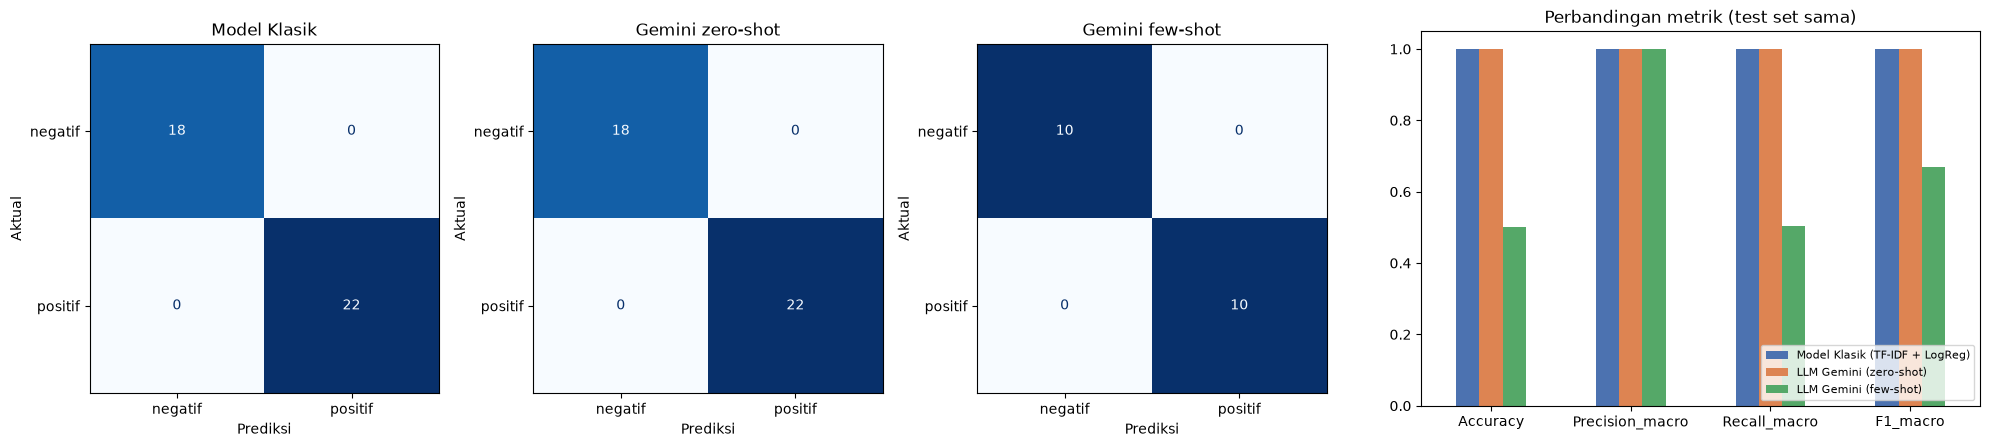

In [17]:
# Visualisasi: confusion matrix ketiga pendekatan + bar chart metrik -> documentation/model_comparison_summary.png
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), gridspec_kw={'width_ratios': [1, 1, 1, 1.6]})
for ax, cm, title in zip(axes[:3], [cm_classic, cm_llm_zero, cm_llm],
                         ['Model Klasik', 'Gemini zero-shot', 'Gemini few-shot']):
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title); ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')

metrics = ['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro']
summary[metrics].T.plot(kind='bar', ax=axes[3], rot=0, color=['#4c72b0', '#dd8452', '#55a868'])
axes[3].set_ylim(0, 1.05); axes[3].set_title('Perbandingan metrik (test set sama)')
axes[3].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(DOCS_DIR / 'model_comparison_summary.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.4 Analisis Kesalahan Prediksi

Menampilkan ulasan yang salah diprediksi oleh masing-masing pendekatan, untuk melihat pola kesalahan.

In [18]:
pd.set_option('display.max_colwidth', 100)
err = test_df[['review_text', 'sentiment', 'pred_classic', 'pred_llm_zero_shot', 'pred_llm_few_shot']]
wrong_any = err[(err['pred_classic'] != err['sentiment']) |
                (err['pred_llm_zero_shot'] != err['sentiment']) |
                (err['pred_llm_few_shot'] != err['sentiment'])]
print(f'Ulasan yang salah diprediksi minimal oleh satu pendekatan: {len(wrong_any)}')
wrong_any

Ulasan yang salah diprediksi minimal oleh satu pendekatan: 20


,review_text,sentiment,pred_classic,pred_llm_zero_shot,pred_llm_few_shot
1,"Puas banget belanja disini, proses cepat dan barang aman.",positif,positif,positif,invalid
30,"Ukuran dan warna berbeda dari pesanan, sangat kecewa.",negatif,negatif,negatif,invalid
135,"Produk original dan berfungsi dengan baik, terima kasih!",positif,positif,positif,invalid
80,"Sangat puas dengan pembelian ini, akan beli lagi di lain waktu.",positif,positif,positif,invalid
9,"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.",positif,positif,positif,invalid
89,"Barangnya bagus banget, sesuai foto dan pengiriman cepat!",positif,positif,positif,invalid
19,"Pelayanan cepat tanggap, produk berkualitas tinggi.",positif,positif,positif,invalid
148,"Barangnya bagus banget, sesuai foto dan pengiriman cepat!",positif,positif,positif,invalid
181,"Produk original dan berfungsi dengan baik, terima kasih!",positif,positif,positif,invalid
136,"Bahan murahan, tidak sesuai dengan harga yang dibayarkan.",negatif,negatif,negatif,invalid


In [19]:
# Contoh kesalahan model klasik pada teks yang belum pernah dilihat (dari GroupKFold)
from sklearn.model_selection import cross_val_predict
cv_pred = cross_val_predict(pipe, X, y, groups=groups, cv=cv)
cv_err = (df.assign(pred_unseen=cv_pred)
            .loc[lambda d: d['pred_unseen'] != d['sentiment'], ['review_text', 'sentiment', 'pred_unseen']]
            .drop_duplicates('review_text'))
print(f'Teks unik yang salah diprediksi model klasik saat teksnya belum pernah dilihat: {len(cv_err)} dari {df["review_text"].nunique()}')
cv_err

Teks unik yang salah diprediksi model klasik saat teksnya belum pernah dilihat: 15 dari 40


,review_text,sentiment,pred_unseen
8,"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.",positif,negatif
12,"Barang cacat produksi, jahitan lepas di beberapa bagian.",negatif,positif
14,Barang tidak berfungsi sama sekali begitu diterima.,negatif,positif
24,"Bahan murahan, tidak sesuai dengan harga yang dibayarkan.",negatif,positif
26,"Kualitas produk sangat memuaskan, akan order lagi.",positif,negatif
27,"Sangat mengecewakan, uang saya seperti terbuang percuma.",negatif,positif
30,"Ukuran dan warna berbeda dari pesanan, sangat kecewa.",negatif,positif
32,"Kualitas produk jelek, baru dipakai sekali sudah rusak.",negatif,positif
36,"Pelayanan ramah dan responsif, barang sampai lebih cepat dari estimasi.",positif,negatif
39,"Produknya rapi dan bersih, tidak ada cacat sama sekali.",positif,negatif


**Pola kesalahan yang perlu diperhatikan:**
- **Model klasik (test set utama)** tidak membuat kesalahan karena hampir semua teks test sudah ada di train.
- **Model klasik (teks baru, GroupKFold)** salah pada 15 dari 40 teks unik, dengan dua pola utama:
  - *Kosakata baru* → ulasan negatif dengan kata kunci yang tidak pernah muncul di training (misal "palsu", "berantakan", "kotor", "murahan", "terburuk") tidak punya bobot, sehingga model jatuh ke kelas mayoritas **positif**. Ini pola dominan (11 dari 15 kesalahan = negatif → positif), artinya keluhan pelanggan lolos tidak terdeteksi.
  - *Negasi* → *"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan."* dan *"Produknya rapi dan bersih, tidak ada cacat sama sekali."* (positif) diprediksi negatif karena kata "tidak", "cacat", dan "mengecewakan" berasosiasi kuat dengan kelas negatif di data training. TF-IDF membaca kata per kata, bukan makna kalimat.
- **LLM** memahami makna kalimat (termasuk negasi dan sinonim) tanpa perlu melihat contoh serupa, tetapi risikonya berbeda: output bisa di luar format (ditangani normalisasi), dan pada ulasan yang benar-benar ambigu/sarkastik model bisa memilih label yang berbeda dari anotator.

## 7. Analisis Trade-off dan Limitation

> ⚠️ Angka yang ditandai **[lihat tabel 6.3]** mengacu pada output yang dihasilkan saat notebook dijalankan. Sesuaikan kalimat bila hasil run kamu berbeda.

### 7.1 Performa
- Pada **test set utama**, model klasik mencapai Accuracy/F1-macro **1,00**, sedangkan LLM **[lihat tabel 6.3]**. Namun skor model klasik di test set ini tergolong *optimistic* karena 98% (39/40) teks test juga ada di train set (duplikasi dataset).
- Pada **teks yang benar-benar baru** (GroupKFold), akurasi model klasik turun drastis ke **±0,60** — hanya sedikit di atas menebak kelas mayoritas (0,55) — dan 11 dari 15 kesalahannya adalah keluhan (negatif) yang diprediksi positif. LLM tidak mengalami penurunan ini karena tidak pernah dilatih dengan data tersebut — skornya di test set sudah merupakan estimasi performa pada data baru.
- Kesimpulan performa: untuk ulasan yang **mirip data training**, model klasik setara dengan LLM; untuk ulasan dengan **gaya bahasa/kosakata baru**, LLM lebih robust.

### 7.2 Effort Implementasi
| Aspek | Model Klasik | LLM API |
|---|---|---|
| Butuh data berlabel | Ya — kualitas & variasi data menentukan hasil | Tidak (zero-shot) / cukup beberapa contoh (few-shot) |
| Proses | Preprocessing, feature engineering, training, tuning, retraining berkala | Rancang prompt, parsing & normalisasi output, error handling/retry |
| Waktu sampai prototipe | Cepat untuk task sederhana, tapi bergantung ketersediaan data | Sangat cepat — bisa langsung dipakai tanpa data |
| Menambah kelas baru (misal "netral") | Perlu labeling ulang & training ulang | Cukup ubah prompt |

### 7.3 Kecepatan
- Model klasik: inferensi dalam hitungan **mikro–milidetik per ulasan**, berjalan lokal di CPU, bisa memproses ribuan ulasan per detik.
- LLM API: latensi **ratusan milidetik sampai beberapa detik per ulasan** (tergantung jaringan & beban server), plus dibatasi **rate limit** (free tier memaksa jeda antar request). Untuk volume besar perlu batching/async dan antrian.
- Perbedaannya bisa ribuan kali lipat **[lihat kolom latensi di tabel 6.3]**.

### 7.4 Biaya
- Model klasik: biaya inferensi praktis **nol** (CPU biasa); biaya utama ada di pengumpulan & labeling data serta maintenance.
- LLM API: biaya **per token** yang tumbuh linear dengan volume ulasan **[lihat estimasi per 1.000 ulasan di tabel 6.3]**. Few-shot lebih mahal daripada zero-shot karena contoh ikut dikirim di setiap request (token input lebih banyak). Untuk platform dengan jutaan ulasan per bulan, biaya ini signifikan dan harus dibandingkan dengan nilai tambah akurasinya.

### 7.5 Limitation
**Model klasik (TF-IDF + Logistic Regression):**
- Hanya mengenali kata yang ada di training (*out-of-vocabulary* tidak punya bobot) → lemah pada sinonim, slang, typo, dan gaya bahasa baru.
- Tidak memahami konteks/urutan kata; negasi hanya tertangkap sebagian lewat bigram.
- Dataset sangat kecil dan repetitif (**40 teks unik**), sehingga skor test set utama bias ke atas; model berisiko *overfit* terhadap template kalimat.
- Butuh retraining setiap ada pergeseran pola bahasa pelanggan.

**LLM API (Gemini):**
- Ketergantungan pada layanan pihak ketiga: *downtime*, rate limit, perubahan/deprecation versi model, dan perubahan harga.
- Output tidak dijamin selalu sesuai format → wajib normalisasi & validasi.
- Meski temperature 0, hasil bisa sedikit berbeda antar versi model → reproducibility jangka panjang tidak terjamin.
- **Privasi data**: teks ulasan dikirim ke server eksternal — perlu dipastikan sesuai kebijakan data perusahaan.
- Latensi lebih tinggi dan biaya per request.
- **Rate limit/kuota**: saat eksperimen, pemanggilan satu ulasan per request langsung terkena error `429 RESOURCE_EXHAUSTED` pada free tier. Solusinya batch prompting (20 ulasan per request). Di produksi dengan volume besar, kuota & rate limit harus direncanakan (paid tier, batching, antrian).

**Limitation eksperimen ini:**
- Test set hanya 40 ulasan (26 teks unik), sehingga selisih 1 prediksi = 2,5 poin akurasi; perbedaan kecil antar pendekatan belum signifikan secara statistik.
- Dataset tidak mengandung ulasan ambigu, sarkasme, atau campuran — padahal di produksi kasus ini umum dan justru di sanalah perbedaan kedua pendekatan paling terasa.

## 8. Rekomendasi Technical Approach

**Rekomendasi: kembangkan pendekatan hybrid — LLM API (Gemini, few-shot) sebagai *labeler* & fallback, model klasik sebagai classifier utama di produksi.**

Secara bertahap:
1. **Fase awal (sekarang):** gunakan **Gemini few-shot** untuk fitur sentimen. Alasannya: data berlabel yang dimiliki tim baru 40 kalimat unik — terlalu sedikit untuk model klasik yang andal pada ulasan baru (terbukti dari penurunan akurasi di uji GroupKFold), sedangkan LLM sudah memberi performa tinggi tanpa training dan tidak terpengaruh kebocoran data.
2. **Kumpulkan data:** simpan prediksi LLM pada ulasan riil sebagai *silver label*, lakukan review manusia pada sampel (terutama prediksi negatif dan kasus ambigu) untuk membangun dataset berlabel yang besar dan beragam.
3. **Fase skala:** latih ulang model klasik (atau model ringan lain) dengan data tersebut. Setelah performanya pada data baru setara LLM, jadikan model klasik classifier utama karena **latensi jauh lebih rendah dan biaya inferensi ~nol** — penting untuk volume ulasan e-commerce yang besar.
4. **Routing:** ulasan yang probabilitas prediksi model klasiknya rendah (tidak yakin, misal 0.4–0.6) diteruskan ke LLM. Dengan begitu, biaya API hanya dikeluarkan untuk sebagian kecil ulasan yang sulit.

**Kenapa bukan salah satu saja?**
- **Hanya model klasik:** skor tinggi di eksperimen ini sebagian besar karena duplikasi data; pada ulasan baru performanya turun, jadi berisiko di produksi.
- **Hanya LLM:** akurat dan fleksibel, tetapi biaya per token, latensi, rate limit, dan ketergantungan vendor menjadi masalah ketika volume ulasan besar dan fitur harus real-time di halaman produk.

Pendekatan hybrid mengambil kekuatan keduanya: robustness & kemudahan LLM di awal, efisiensi model klasik saat skala besar.